# [GSE50760](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE50760)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2021-06-21
> - Modified: 2025-01-19

# 1. Experimental Design

> Gene expression profiling study by RNA-seq in colorectal cancer.
> - Kim Seon-Kyu, Kim Seon-Young, Kim Jeong-Hwan, Roh Seon Ae, Cho Dong-Hyung, Kim Yong Sung and Kim Jin Cheon, (2014), A nineteen gene-based risk score classifier predicts prognosis of colorectal cancer patients, Molecular Oncology, 8, doi: 10.1016/j.molonc.2014.06.016.
> - polyA RNA-seq
> - Illumina HiSeq 2000, PE100
> - hg38

| Sample | Organism | Tissue | Source | Status | AJCC Stage | Patient |
| - | - | - | - | - | - | - |
| Normal | Homo sapiens | CRC | Normal-looking surrounding colonic epithelium | Normal | Stage IV | rep1~18 |
| Primary | Homo sapiens | CRC | Primary colorectal cancer | Primary | Stage IV | rep1~18 |
| Metastasis | Homo sapiens | CRC | Metastatic colorectal cancer to the liver | Metastasis | Stage IV | rep1~18 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Hs_CRC_GSE50760/02_output"

### a). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    # sub("^02_output/03_align/(.*?).bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)

[1] 78686    62

In [4]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("CRC"))) |>
    separate(
        col = sample, into = c("Tissue", "Group", "Patient"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_", "", sample),
        Group = factor(Group, levels = c("Normal", "Primary", "Metastasis")), 
        Patient = factor(Patient)) |> 
    arrange(Group, Patient) |>
    column_to_rownames("sample")

head(coldata)

,Tissue,Group,Patient
,<chr>,<fct>,<fct>
Normal_AMC02,CRC,Normal,AMC02
Normal_AMC03,CRC,Normal,AMC03
Normal_AMC05,CRC,Normal,AMC05
Normal_AMC06,CRC,Normal,AMC06
Normal_AMC07,CRC,Normal,AMC07
Normal_AMC08,CRC,Normal,AMC08


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("CRC")) |>
    rename_with(~ sub("^[^_]+_", "", .x)) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group)

class: DESeqDataSet 
dim: 78686 54 
metadata(1): version
assays(1): counts
rownames(78686): ENSG00000290825.2 ENSG00000223972.6 ...
  ENSG00000210195.2 ENSG00000210196.2
rowData names(3): symbol type basepairs
colnames(54): Normal_AMC02 Normal_AMC03 ... Metastasis_AMC23
  Metastasis_AMC24
colData names(3): Tissue Group Patient

### b). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE)

In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Tissue", "Group", "Patient"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sampleName = sub("^[^_]+_", "", sampleName),
        Group = factor(Group, levels = c("Normal", "Primary", "Metastasis")), 
        Patient = factor(Patient)) |> 
    arrange(Group, Patient) |>
    select("sampleName", "fileName", "Tissue", "Group", "Patient") |>
    as.data.frame()

head(coldata)

,sampleName,fileName,Tissue,Group,Patient
,<chr>,<chr>,<chr>,<fct>,<fct>
1,Normal_AMC02,CRC_Normal_AMC02.tsv,CRC,Normal,AMC02
2,Normal_AMC03,CRC_Normal_AMC03.tsv,CRC,Normal,AMC03
3,Normal_AMC05,CRC_Normal_AMC05.tsv,CRC,Normal,AMC05
4,Normal_AMC06,CRC_Normal_AMC06.tsv,CRC,Normal,AMC06
5,Normal_AMC07,CRC_Normal_AMC07.tsv,CRC,Normal,AMC07
6,Normal_AMC08,CRC_Normal_AMC08.tsv,CRC,Normal,AMC08


In [10]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Group,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 78686 54 
metadata(1): version
assays(1): counts
rownames(78686): ENSG00000000003.16 ENSG00000000005.6 ...
  ENSG00000310576.1 ENSG00000310577.1
rowData names(0):
colnames(54): Normal_AMC02 Normal_AMC03 ... Metastasis_AMC23
  Metastasis_AMC24
colData names(3): Tissue Group Patient

### c). Salmon

#### tximport

In [11]:
gtf <- rtracklayer::import(
    "~/reference/Homo_sapiens/hg38/gencode.v48.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

In [12]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE)
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

In [13]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Tissue", "Group", "Patient"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_", "", sample),
        Group = factor(Group, levels = c("Normal", "Primary", "Metastasis")), 
        Patient = factor(Patient)) |> 
    arrange(Group, Patient) |>
    column_to_rownames("sample")

names(salmon_quants) <- sub("^[^_]+_", "", names(salmon_quants))
salmon_quants <- salmon_quants[rownames(coldata)]

head(coldata)

,Tissue,Group,Patient
,<chr>,<fct>,<fct>
Normal_AMC02,CRC,Normal,AMC02
Normal_AMC03,CRC,Normal,AMC03
Normal_AMC05,CRC,Normal,AMC05
Normal_AMC06,CRC,Normal,AMC06
Normal_AMC07,CRC,Normal,AMC07
Normal_AMC08,CRC,Normal,AMC08


In [14]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 
32 
33 
34 
35 
36 
37 
38 
39 
40 
41 
42 
43 
44 
45 
46 
47 
48 
49 
50 
51 
52 
53 
54 


transcripts missing from tx2gene: 11088

summarizing abundance

summarizing counts

summarizing length



In [15]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 78241 54 
metadata(1): version
assays(2): counts avgTxLength
rownames(78241): ENSG00000000003.16 ENSG00000000005.6 ...
  ENSG00000310576.1 ENSG00000310577.1
rowData names(0):
colnames(54): Normal_AMC02 Normal_AMC03 ... Metastasis_AMC23
  Metastasis_AMC24
colData names(3): Tissue Group Patient

#### tximeta

In [16]:
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE)

In [17]:
coldata <- tibble(
    names = salmon_dirs, 
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")) |> 
    separate(
        col = names, into = c("Tissue", "Group", "Patient"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        names = sub("^[^_]+_", "", names),
        Group = factor(Group, levels = c("Normal", "Primary", "Metastasis")), 
        Patient = factor(Patient)) |> 
    arrange(Group, Patient) |>
    select("names", "files", "Tissue", "Group", "Patient") |>
    as.data.frame()

coldata |> dplyr::select(-one_of("files")) |> head()

,names,Tissue,Group,Patient
,<chr>,<chr>,<fct>,<fct>
1,Normal_AMC02,CRC,Normal,AMC02
2,Normal_AMC03,CRC,Normal,AMC03
3,Normal_AMC05,CRC,Normal,AMC05
4,Normal_AMC06,CRC,Normal,AMC06
5,Normal_AMC07,CRC,Normal,AMC07
6,Normal_AMC08,CRC,Normal,AMC08


In [18]:
# suppressPackageStartupMessages(library(tximeta))
tximeta::makeLinkedTxome(
    indexDir = "~/reference/Homo_sapiens/hg38/index/salmon_index", 
    source = "GENCODE", organism = "Homo sapiens", 
    release = "48", genome = "GRCh38",
    fasta = "~/reference/Homo_sapiens/hg38/gencode.v48.transcripts.fa", 
    gtf = "~/reference/Homo_sapiens/hg38/index/genome.gtf", 
    write = FALSE)

reading digest from indexDir: ~/reference/Homo_sapiens/hg38/index/salmon_index

NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE

saving linkedTxome in bfc (first time)



In [19]:
# There is a network problem
se <- tximeta::tximeta(coldata, useHub = FALSE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 
32 
33 
34 
35 
36 
37 
38 
39 
40 
41 
42 
43 
44 
45 
46 
47 
48 
49 
50 
51 
52 
53 
54 


found matching linkedTxome:
[ GENCODE - Homo sapiens - release 48 ]

building TxDb with 'txdbmaker' package

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"
OK

generating transcript ranges

Warning message in checkAssays2Txps(assays, txps):
"

11088 out of 395452 txps were missing from GTF/GFF but were in the indexed FASTA
(e

In [20]:
DESeqDataSet(gse, design = ~ Group)

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 78241 54 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(78241): ENSG00000000003.16 ENSG00000000005.6 ...
  ENSG00000310576.1 ENSG00000310577.1
rowData names(2): gene_id tx_ids
colnames(54): Normal_AMC02 Normal_AMC03 ... Metastasis_AMC23
  Metastasis_AMC24
colData names(4): names Tissue Group Patient

### d). kallisto

#### tximport

In [21]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE)
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

In [22]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Tissue", "Group", "Patient"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_", "", sample),
        Group = factor(Group, levels = c("Normal", "Primary", "Metastasis")), 
        Patient = factor(Patient)) |> 
    arrange(Group, Patient) |>
    column_to_rownames("sample")

names(kallisto_quants) <- sub("^[^_]+_", "", names(kallisto_quants))
kallisto_quants <- kallisto_quants[rownames(coldata)]

head(coldata)

,Tissue,Group,Patient
,<chr>,<fct>,<fct>
Normal_AMC02,CRC,Normal,AMC02
Normal_AMC03,CRC,Normal,AMC03
Normal_AMC05,CRC,Normal,AMC05
Normal_AMC06,CRC,Normal,AMC06
Normal_AMC07,CRC,Normal,AMC07
Normal_AMC08,CRC,Normal,AMC08


In [23]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 
32 
33 
34 
35 
36 
37 
38 
39 
40 
41 
42 
43 
44 
45 
46 
47 
48 
49 
50 
51 
52 
53 
54 


transcripts missing from tx2gene: 26375

summarizing abundance

summarizing counts

summarizing length



In [24]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 78686 54 
metadata(1): version
assays(2): counts avgTxLength
rownames(78686): ENSG00000000003.16 ENSG00000000005.6 ...
  ENSG00000310576.1 ENSG00000310577.1
rowData names(0):
colnames(54): Normal_AMC02 Normal_AMC03 ... Metastasis_AMC23
  Metastasis_AMC24
colData names(3): Tissue Group Patient

## 2). Object Construction

In [25]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 78686 54 
metadata(0):
assays(1): counts
rownames(78686): ENSG00000290825.2 ENSG00000223972.6 ...
  ENSG00000210195.2 ENSG00000210196.2
rowData names(3): symbol type basepairs
colnames(54): Normal_AMC02 Normal_AMC03 ... Metastasis_AMC23
  Metastasis_AMC24
colData names(3): Tissue Group Patient

In [26]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group)

dds

class: DESeqDataSet 
dim: 78686 54 
metadata(1): version
assays(1): counts
rownames(78686): ENSG00000290825.2 ENSG00000223972.6 ...
  ENSG00000210195.2 ENSG00000210196.2
rowData names(3): symbol type basepairs
colnames(54): Normal_AMC02 Normal_AMC03 ... Metastasis_AMC23
  Metastasis_AMC24
colData names(3): Tissue Group Patient

In [27]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [28]:
keep <- rowSums(assay(eSet) >= 10) >= 18
# keep <- rowSums(counts(dds) >= 10) >= 18

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 19032 
 Remove: 59654 
 Retention rate: 24.19 %


In [29]:
keep <- filterByExpr(dgel, group = dgel$samples$group)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 19236 
 Remove: 59450 
 Retention rate: 24.45 %


# 3. Normalization

In [30]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [31]:
vsd <- vst(dds, blind = FALSE)

In [32]:
dds <- estimateSizeFactors(dds)
norm_fpkm <- fpkm(dds, robust = TRUE)

In [33]:
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [34]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [35]:
suppressPackageStartupMessages(library(vsn))

In [36]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [37]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(vsd), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


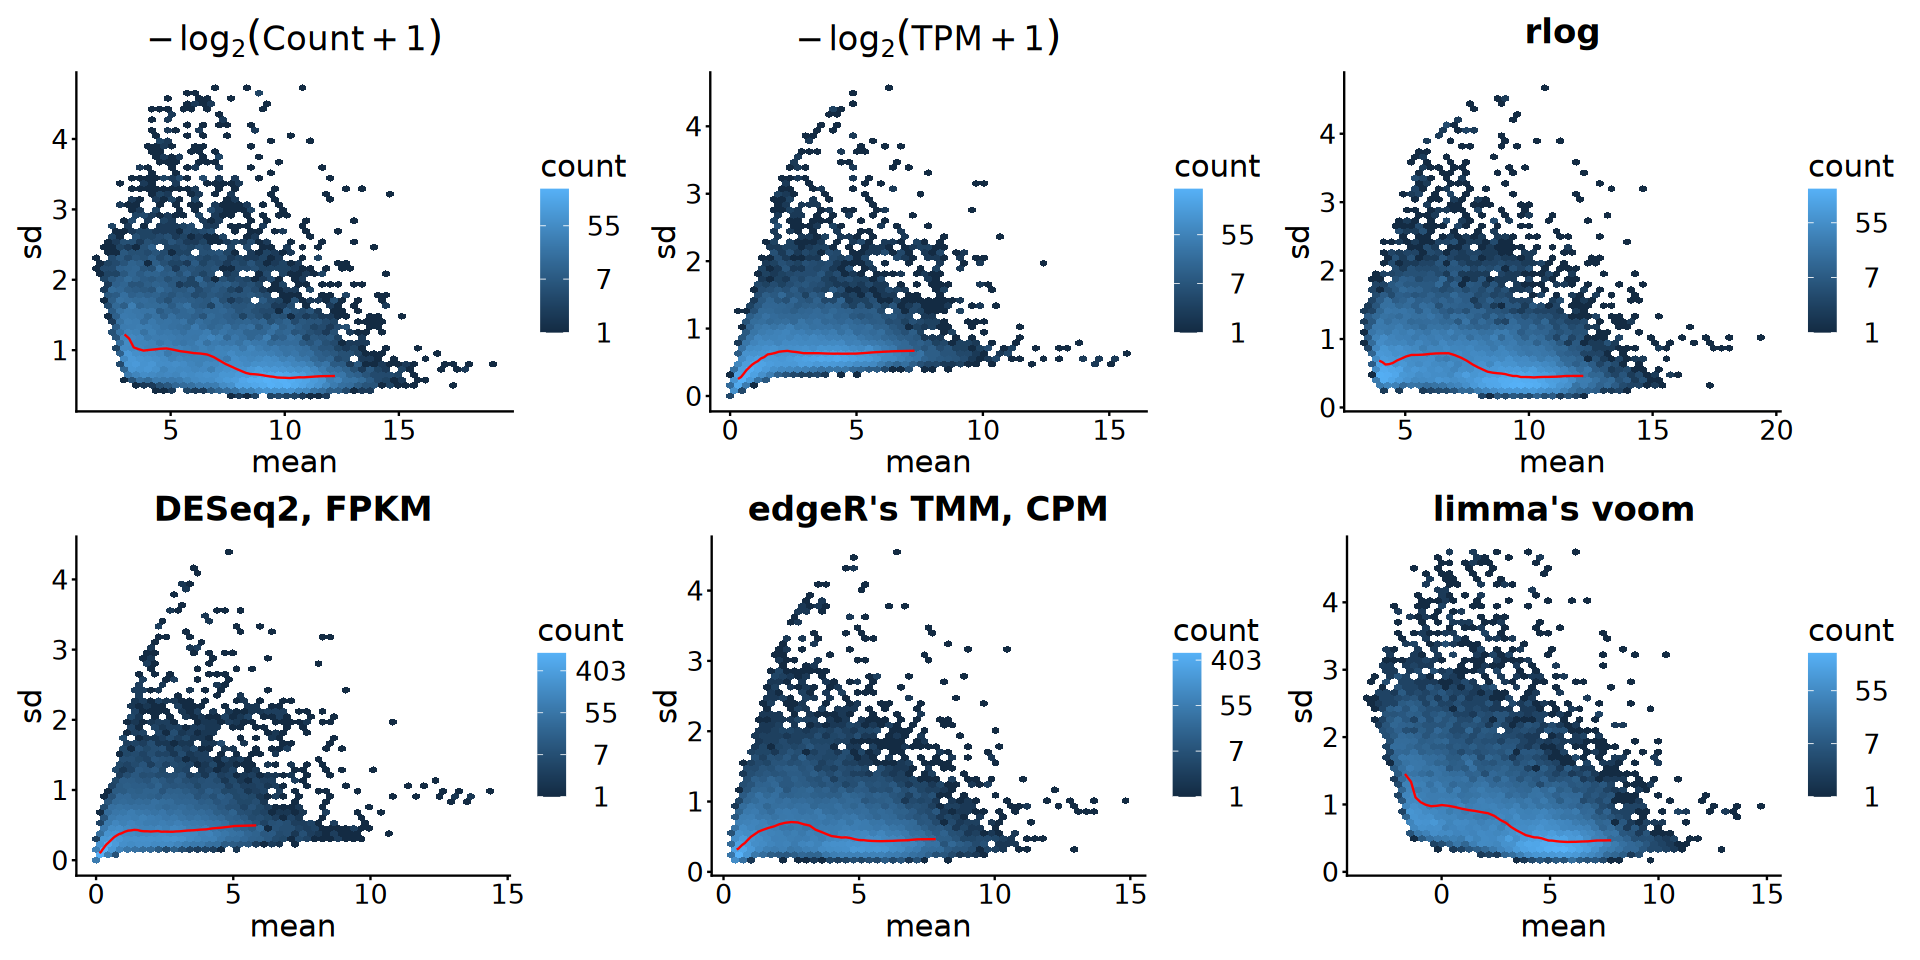

In [38]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [39]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(vsd)

### 1). Overview

In [40]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Patient) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

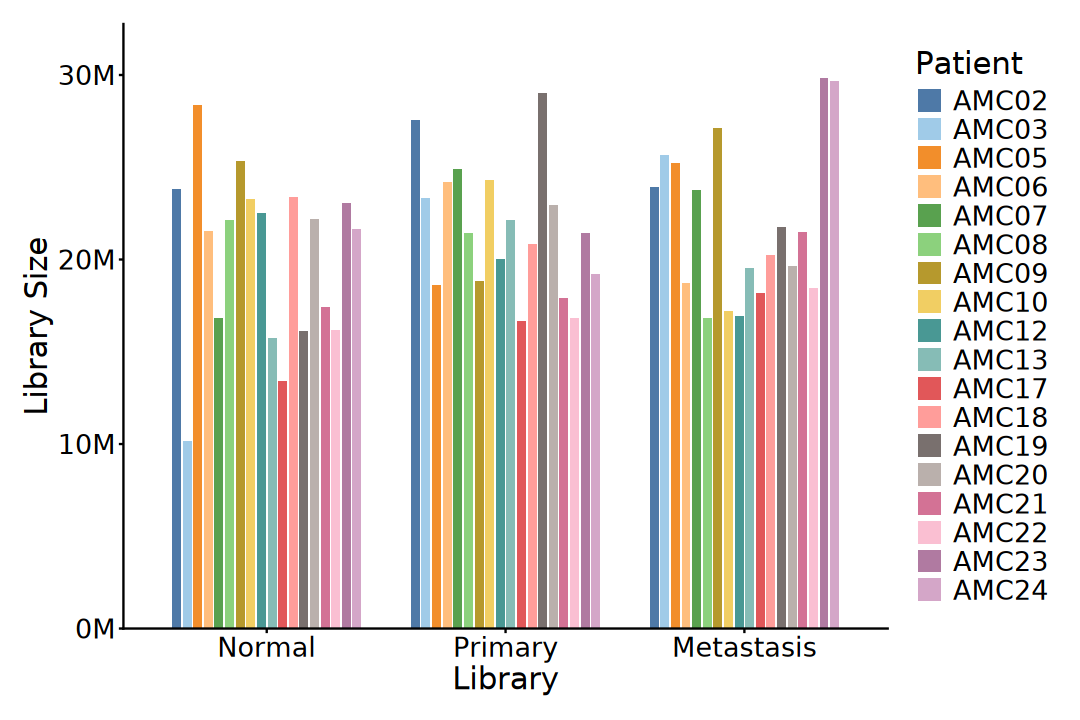

In [41]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize, group = Patient)) +
    geom_bar(
        aes(fill = Patient), stat = "identity", 
        position = position_dodge(width = 0.8), 
        width = 0.6, linewidth = 1.5) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"), 
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    ggthemes::scale_color_tableau(palette = "Tableau 20") + 
    ggthemes::scale_fill_tableau(palette = "Tableau 20") + 
    labs(x = "Library", y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

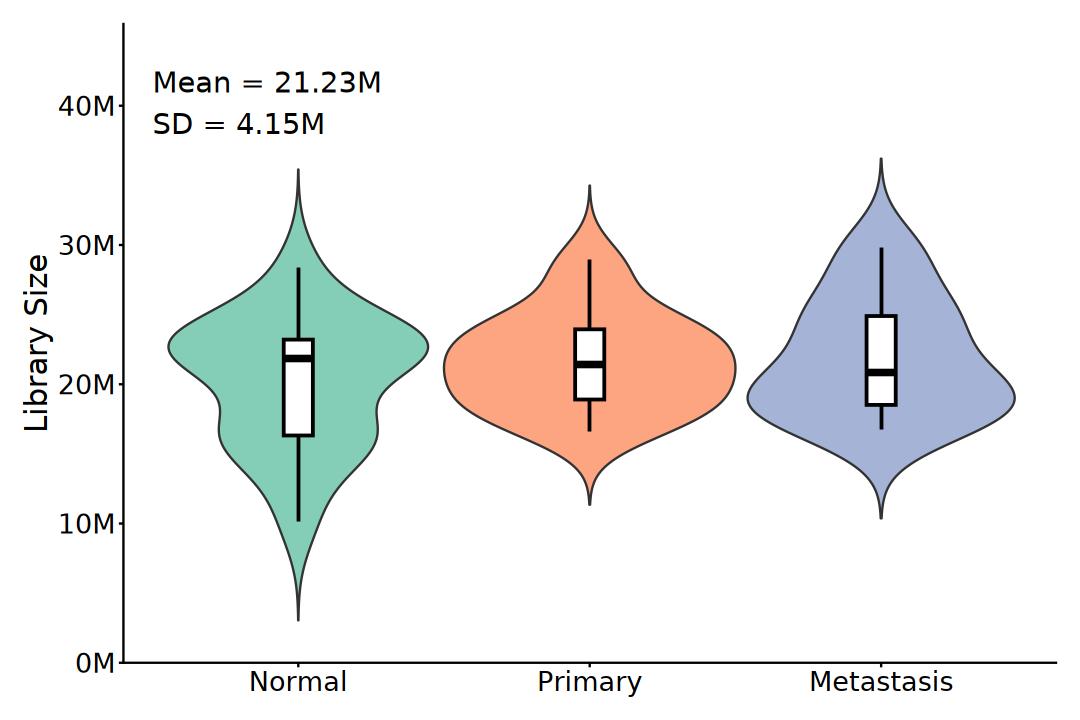

In [42]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize)) +
    geom_violin(
        aes(fill = Group), width = 1, alpha = 0.8,
        trim = FALSE, show.legend = FALSE) +
    geom_boxplot(
        color = "black", fill = "white", width = 0.1, 
        linewidth = 0.8, show.legend = FALSE) +
    annotate(
        geom = "text", x = .5, y = max(plot_df$librarySize) * 1.4,
        label = paste0("Mean = ", round(mean(plot_df$librarySize) / 1e6 , 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = .5, y = max(plot_df$librarySize) * 1.3,
        label = paste0("SD = ", round(sd(plot_df$librarySize) * 1e-6 , 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"), 
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 2). PCA

In [43]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [44]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [45]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group), size = 5, alpha = 0.6) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [46]:
pca_res <- plotPCA(
    vsd, intgroup = c("Group"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [47]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group), size = 5, alpha = 0.6) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [48]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [49]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group), size = 5, alpha = 0.6) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

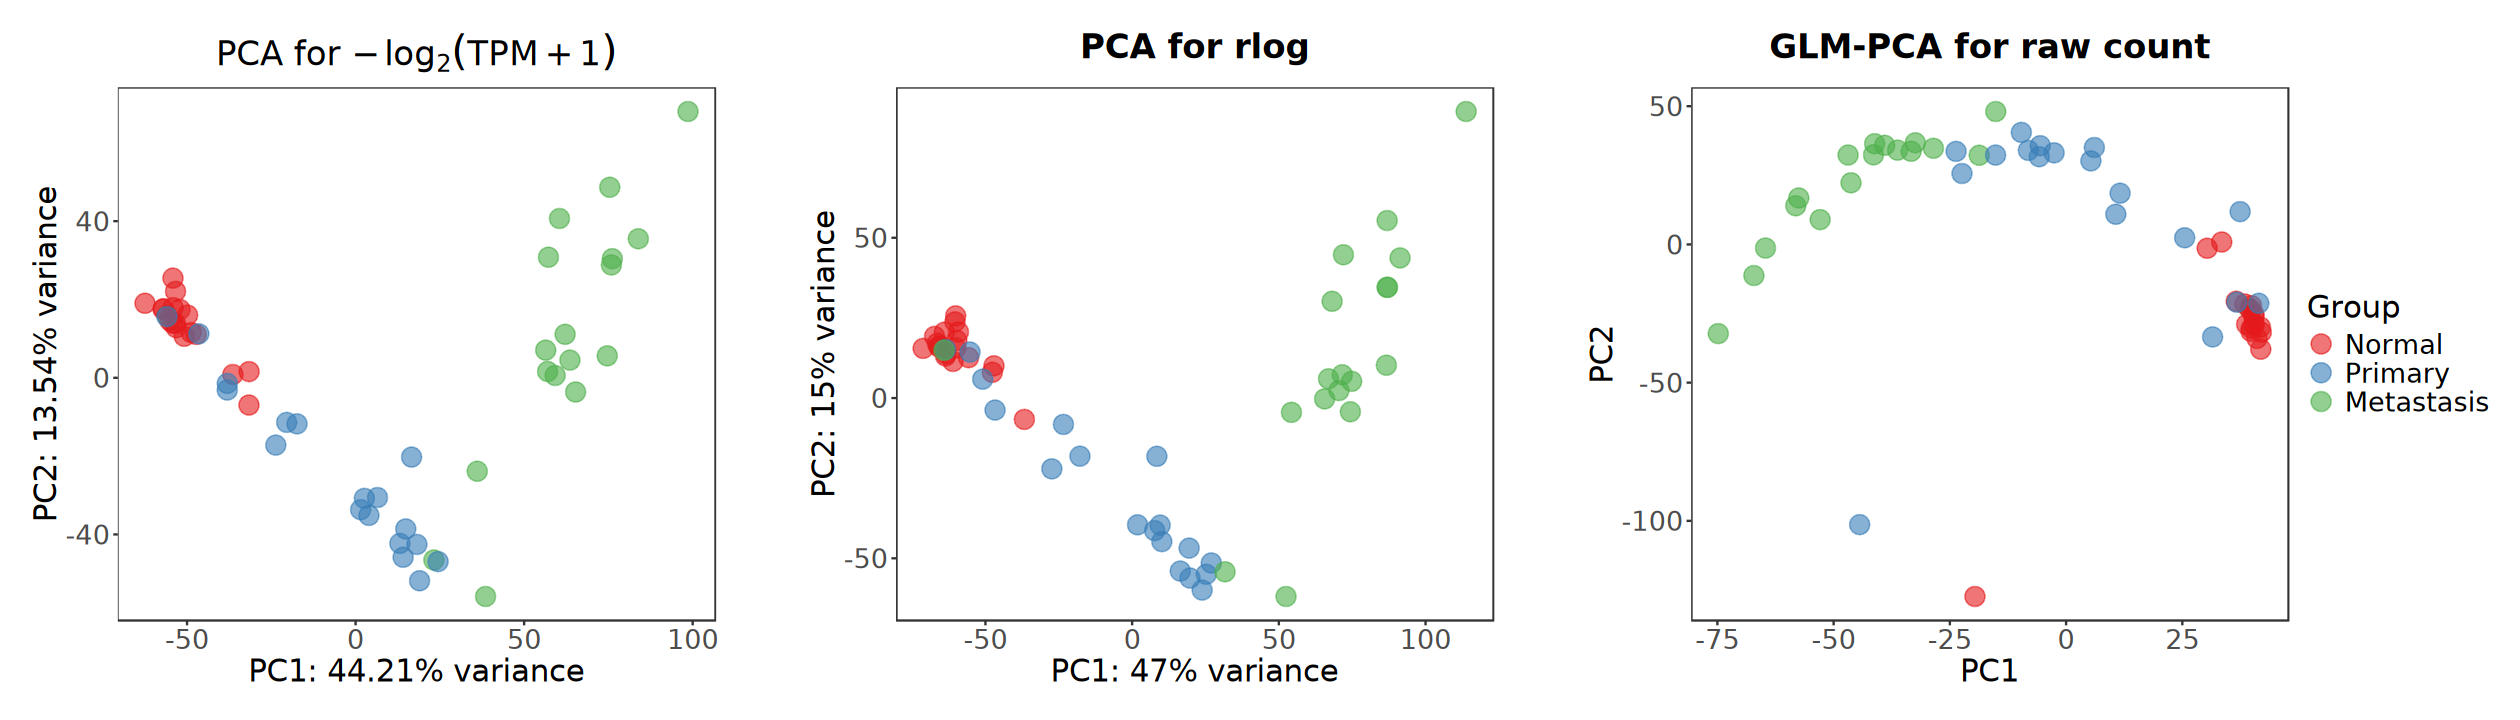

In [50]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [51]:
dist_mat <- norm_mat[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

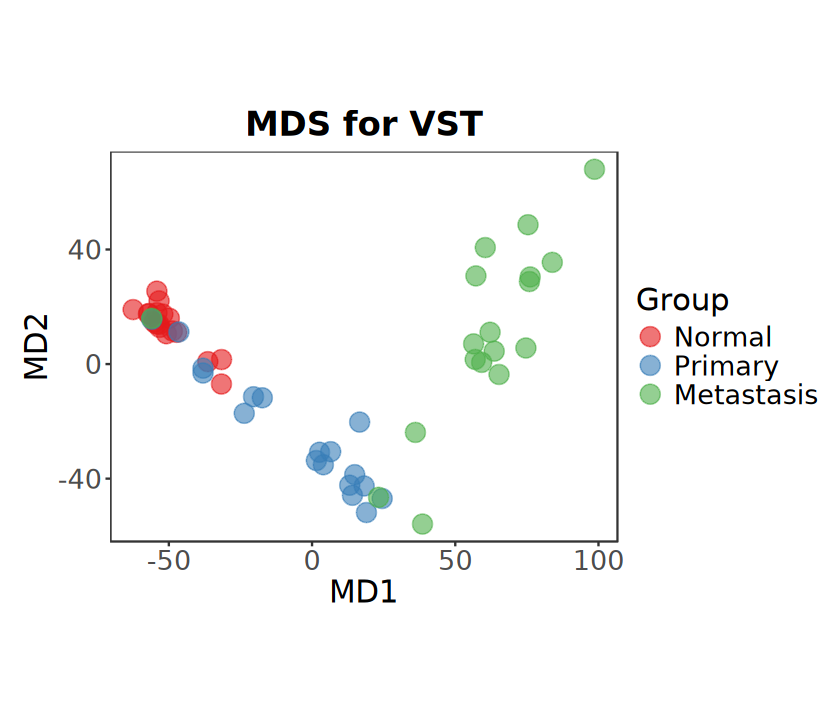

In [52]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group), size = 5, alpha = 0.6) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    ggtitle("MDS for VST") + 
    labs(x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [53]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

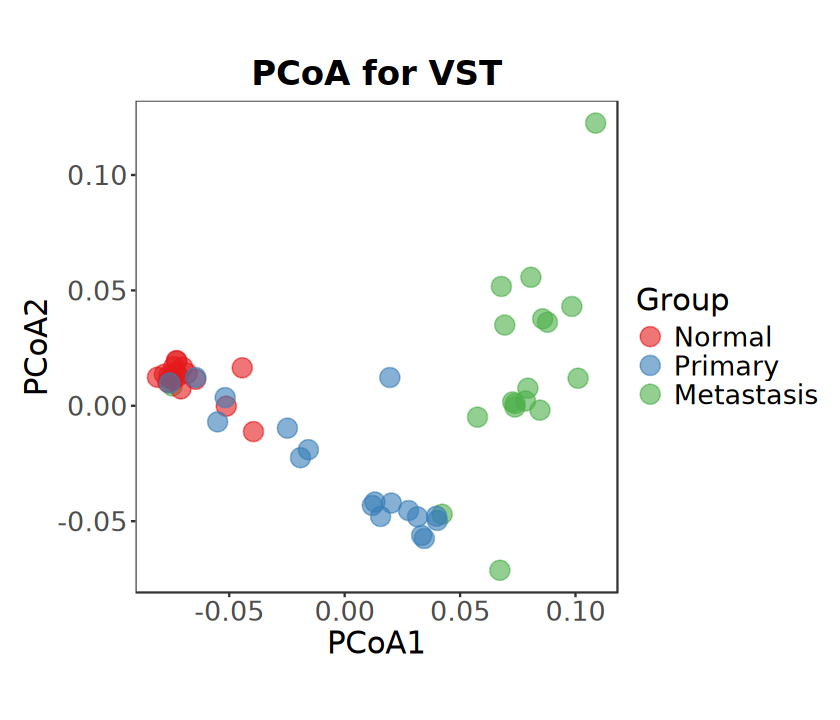

In [54]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Group), size = 5, alpha = 0.6) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    ggtitle("PCoA for VST") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [55]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Group)

In [56]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))

anno_colors <- list(Group = group_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [57]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

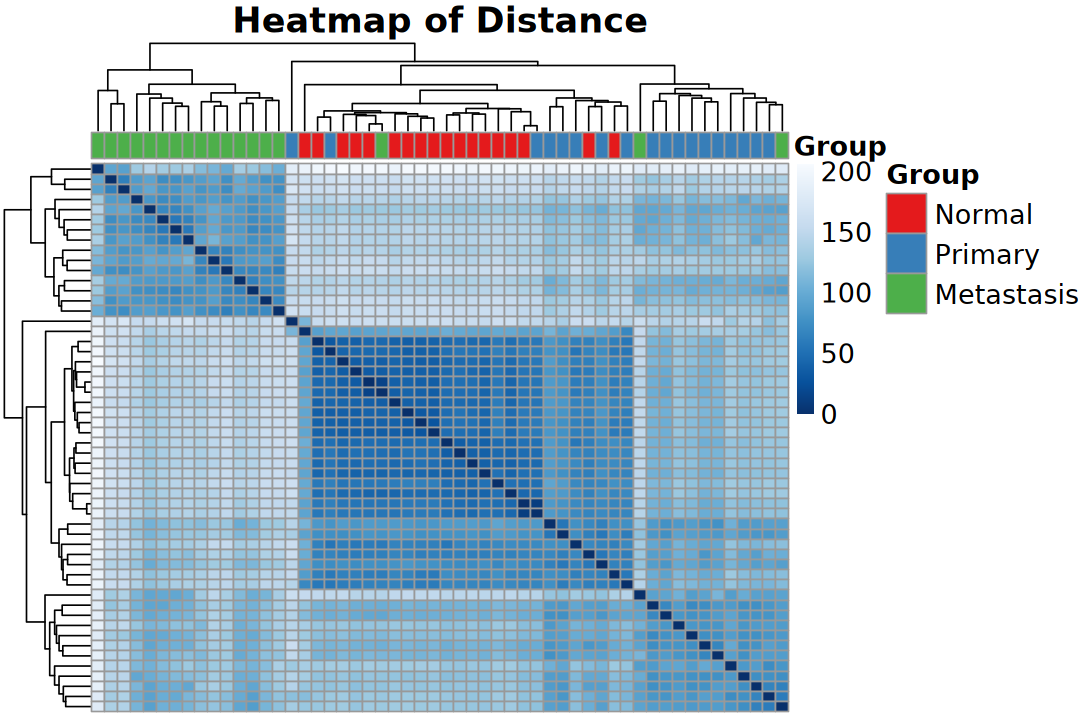

In [58]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [59]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

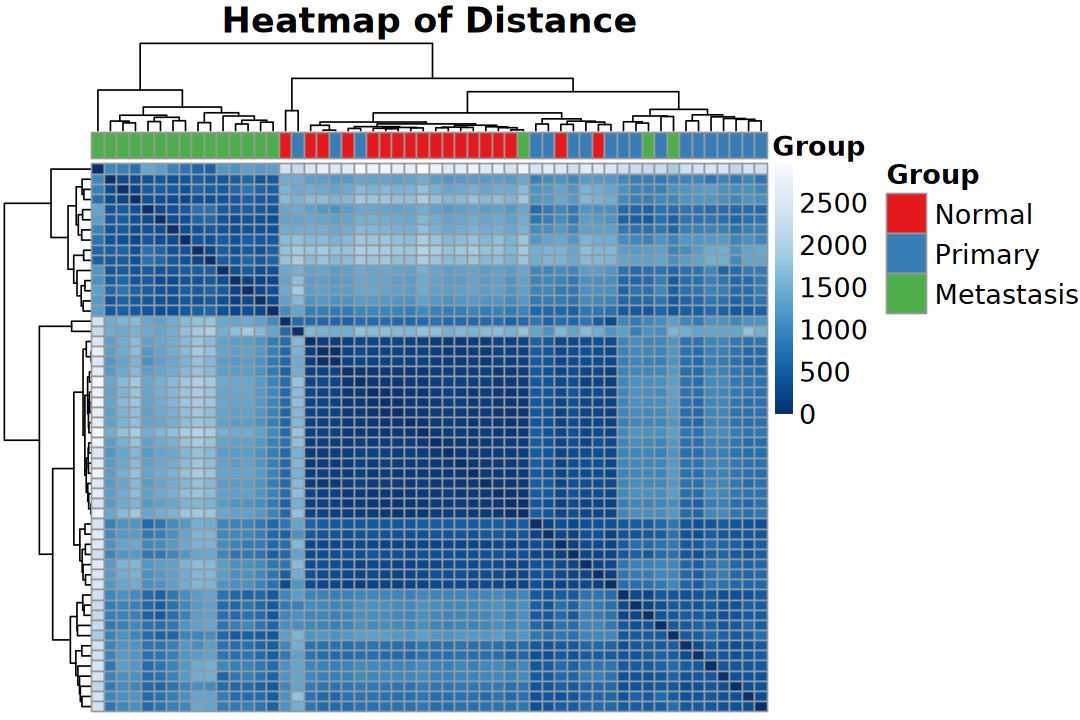

In [60]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [61]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

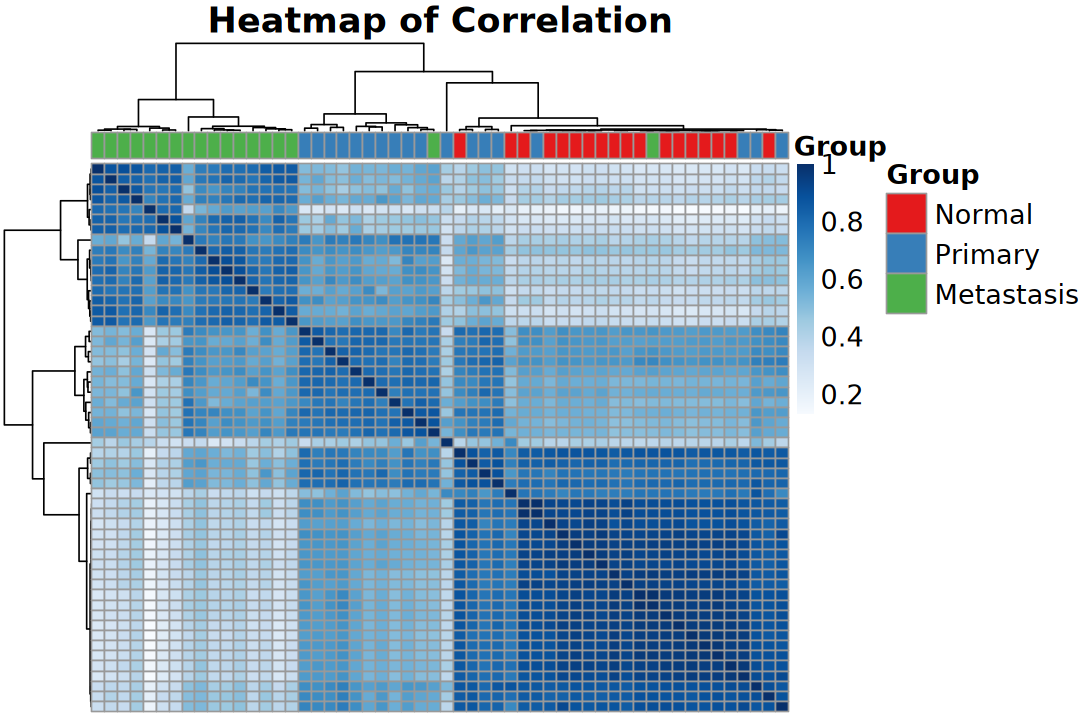

In [62]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

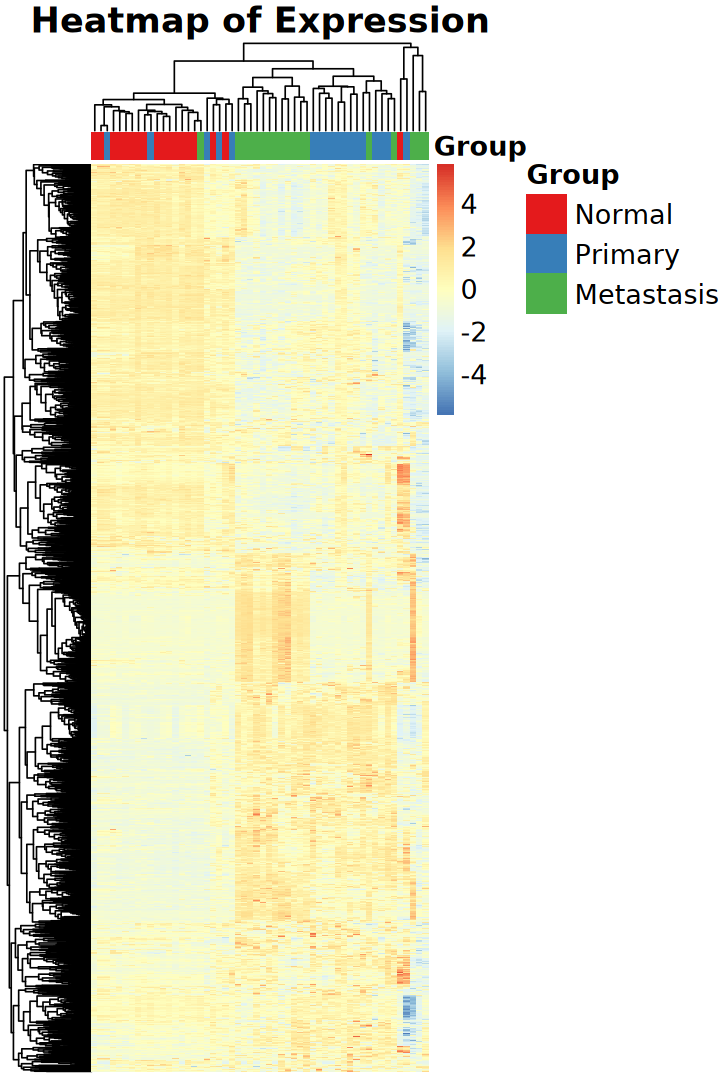

In [63]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs

In [64]:
logfc_cutoff <- log2(4)
p_cutoff <- 0.05

## 1). DESeq2

> median of ratios for normalization

In [65]:
design(dds) <- ~ 0 + Group
design(dds)

~0 + Group

In [66]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

-- replacing outliers and refitting for 539 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)

estimating dispersions

fitting model and testing



In [67]:
resultsNames(dds)

[1] "GroupNormal"     "GroupPrimary"    "GroupMetastasis"

In [68]:
contrast_pairs <- levels(dds$Group) |>
    combn(2, simplify = FALSE)
contrast_pairs

contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[2], "_vs_", .x[1]))
contrast_labels

[[1]]
[1] "Normal"  "Primary"

[[2]]
[1] "Normal"     "Metastasis"

[[3]]
[1] "Primary"    "Metastasis"

[1] "Primary_vs_Normal"     "Metastasis_vs_Normal"  "Metastasis_vs_Primary"

### a). Standard

In [69]:
deseq2_result_list <- map(contrast_pairs, function(lv) {
    results(dds, contrast = c("Group", lv[2], lv[1])) |>
        as.data.frame() |> 
        rownames_to_column("gene_id") |>
        dplyr::rename(logFC = log2FoldChange) |>
        mutate(
            method = "DESeq2",
            contrast = paste0(lv[2], "_vs_", lv[1]),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS"))) |>
        left_join(
            rowData(dds) |> as.data.frame() |> 
                dplyr::select(symbol, type, basepairs) |>
                rownames_to_column("gene_id"), 
            by = "gene_id")
}) |> set_names(contrast_labels)

In [70]:
deseq2_result_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deseq2_result_df$contrast, deseq2_result_df$result)

                       
                           Up  Down    NS
  Primary_vs_Normal       394   111 18527
  Metastasis_vs_Normal    804   904 17324
  Metastasis_vs_Primary   356   301 18375

### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.
>
> Notes:
> - `apeglm` shrunken LFC requires specific coefficients from resultsNames(dds). Re-leveling the reference group is necessary to compute contrasts not inherently present in the initial design matrix.

In [71]:
deseq2_lfc_result_list <- map(contrast_pairs, function(lv) {
    lfcShrink(dds, contrast = c("Group", lv[2], lv[1]), type = "ashr") |>
        as.data.frame() |> 
        rownames_to_column("gene_id") |>
        dplyr::rename(logFC = log2FoldChange) |>
        mutate(
            method = "DESeq2-lfcShrink",
            contrast = paste0(lv[2], "_vs_", lv[1]),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS"))) |>
        left_join(
            rowData(dds) |> as.data.frame() |> 
                dplyr::select(symbol, type, basepairs) |>
                rownames_to_column("gene_id"), 
            by = "gene_id")
}) |> set_names(contrast_labels)

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041



In [72]:
deseq2_lfc_result_df <- bind_rows(deseq2_lfc_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deseq2_lfc_result_df$contrast, deseq2_lfc_result_df$result)

                       
                           Up  Down    NS
  Primary_vs_Normal       257    24 18751
  Metastasis_vs_Normal    718   741 17573
  Metastasis_vs_Primary   319   212 18501

In [73]:
comparison_df <- deseq2_result_df |> 
    dplyr::select(gene_id, contrast, result_raw = result) |> 
    inner_join(
        deseq2_lfc_result_df |> 
            dplyr::select(gene_id, contrast, result_lfc = result),
        by = c("gene_id", "contrast"))

comparison_df |> 
    group_split(contrast) |> 
    walk(function(sub_df) {
        cat("\n=========================================\n")
        cat("Contrast:", as.character(unique(sub_df$contrast)), "\n")
        cat("=========================================\n")
        print(table(Raw = sub_df$result_raw, LFC_Shrink = sub_df$result_lfc))
    })


Contrast: Primary_vs_Normal 
      LFC_Shrink
Raw       Up  Down    NS
  Up     257     0   137
  Down     0    24    87
  NS       0     0 18527

Contrast: Metastasis_vs_Normal 
      LFC_Shrink
Raw       Up  Down    NS
  Up     718     0    86
  Down     0   741   163
  NS       0     0 17324

Contrast: Metastasis_vs_Primary 
      LFC_Shrink
Raw       Up  Down    NS
  Up     319     0    37
  Down     0   212    89
  NS       0     0 18375


## 2). edgeR

> Trimmed Mean of M-values (TMM)

In [74]:
design <- model.matrix(~ 0 + group, data = dgel$samples)
colnames(design) <- levels(dgel$samples$group)
head(design)

,Normal,Primary,Metastasis
Normal_AMC02,1,0,0
Normal_AMC03,1,0,0
Normal_AMC05,1,0,0
Normal_AMC06,1,0,0
Normal_AMC07,1,0,0
Normal_AMC08,1,0,0


In [75]:
contrast_pairs <- levels(dgel$samples$group) |>
    combn(2, simplify = FALSE)
contrast_pairs

contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[2], "_vs_", .x[1]))
contrast_labels

contrast_matrix <- contrast_pairs |> 
    map(function(lv) {paste0(lv[2], "-", lv[1])}) |>
    makeContrasts(contrasts = _, levels = design)
contrast_matrix

[[1]]
[1] "Normal"  "Primary"

[[2]]
[1] "Normal"     "Metastasis"

[[3]]
[1] "Primary"    "Metastasis"

[1] "Primary_vs_Normal"     "Metastasis_vs_Normal"  "Metastasis_vs_Primary"

,Primary-Normal,Metastasis-Normal,Metastasis-Primary
Normal,-1,-1,0
Primary,1,0,-1
Metastasis,0,1,1


### a). Negative binomial GLM framework

In [76]:
dgel <- estimateDisp(dgel, design)
# likelihood ratio test
fit <- glmFit(dgel, design)

In [77]:
edger_result_list <- map(colnames(contrast_matrix), function(idx) {
    glmLRT(fit, contrast = contrast_matrix[, idx]) |>
        topTags(n = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = FDR, pvalue = PValue) |>
        mutate(
            method = "edgeR-lrt",
            contrast = gsub(idx, pattern = "-", replacement = "_vs_"),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}) |> set_names(contrast_labels)

In [78]:
edger_result_df <- bind_rows(edger_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(edger_result_df$contrast, edger_result_df$result)

                       
                           Up  Down    NS
  Primary_vs_Normal       434   110 18692
  Metastasis_vs_Normal    881   941 17414
  Metastasis_vs_Primary   379   312 18545

### b). Quasi-likelihood pipeline (edgeR v3)

In [79]:
dgel <- estimateDisp(dgel, design)
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)

In [80]:
edger_qlf_result_list <- map(colnames(contrast_matrix), function(idx) {
    glmQLFTest(fit, contrast = contrast_matrix[, idx]) |>
        topTags(n = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = FDR, pvalue = PValue) |>
        mutate(
            method = "edgeR",
            contrast = gsub(idx, pattern = "-", replacement = "_vs_"),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}) |> set_names(contrast_labels)

In [81]:
edger_qlf_result_df <- bind_rows(edger_qlf_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(edger_qlf_result_df$contrast, edger_qlf_result_df$result)

                       
                           Up  Down    NS
  Primary_vs_Normal       434   116 18686
  Metastasis_vs_Normal    884   918 17434
  Metastasis_vs_Primary   381   288 18567

In [82]:
comparison_df <- edger_result_df |> 
    dplyr::select(gene_id, contrast, result_lrt = result) |> 
    inner_join(
        edger_qlf_result_df |> 
            dplyr::select(gene_id, contrast, result_qlf = result),
        by = c("gene_id", "contrast"))

comparison_df |> 
    group_split(contrast) |> 
    walk(function(sub_df) {
        cat("\n=========================================\n")
        cat("Contrast:", as.character(unique(sub_df$contrast)), "\n")
        cat("=========================================\n")
        print(table(LRT = sub_df$result_lrt, QLF = sub_df$result_qlf))
    })


Contrast: Primary_vs_Normal 
      QLF
LRT       Up  Down    NS
  Up     433     0     1
  Down     0   108     2
  NS       1     8 18683

Contrast: Metastasis_vs_Normal 
      QLF
LRT       Up  Down    NS
  Up     881     0     0
  Down     0   917    24
  NS       3     1 17410

Contrast: Metastasis_vs_Primary 
      QLF
LRT       Up  Down    NS
  Up     377     0     2
  Down     0   286    26
  NS       4     2 18539


## 3). limma

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

In [83]:
design <- model.matrix(~ 0 + group, data = dgel$samples)
colnames(design) <- levels(dgel$samples$group)

In [84]:
contrast_pairs <- levels(dgel$samples$group) |>
    combn(2, simplify = FALSE)
contrast_pairs

contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[2], "_vs_", .x[1]))
contrast_labels

contrast_matrix <- contrast_pairs |> 
    map(function(lv) {paste0(lv[2], "-", lv[1])}) |>
    makeContrasts(contrasts = _, levels = design)
contrast_matrix

[[1]]
[1] "Normal"  "Primary"

[[2]]
[1] "Normal"     "Metastasis"

[[3]]
[1] "Primary"    "Metastasis"

[1] "Primary_vs_Normal"     "Metastasis_vs_Normal"  "Metastasis_vs_Primary"

,Primary-Normal,Metastasis-Normal,Metastasis-Primary
Normal,-1,-1,0
Primary,1,0,-1
Metastasis,0,1,1


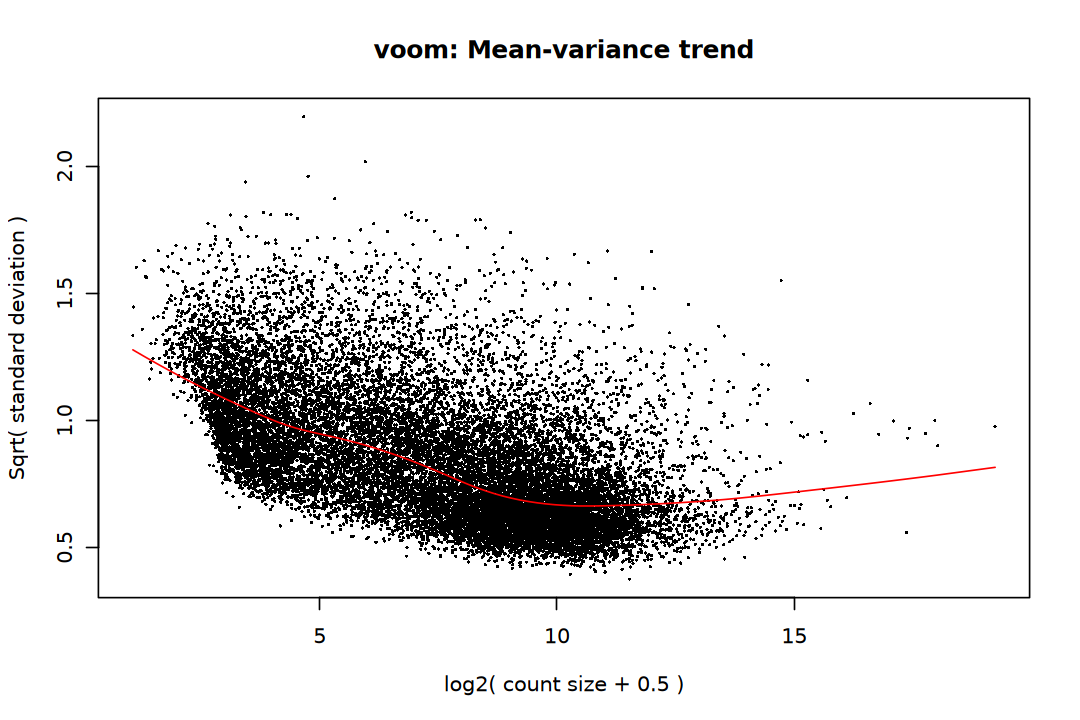

In [85]:
options(repr.plot.width = 9, repr.plot.height = 6)

norm_v <- voom(dgel, design, plot = TRUE)

In [86]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Compute contrasts from linear model fit
fit <- contrasts.fit(fit, contrast_matrix)
# Empirical Bayes Statistics for Differential Expression
fit <- eBayes(fit)

In [87]:
limma_result_list <- map(colnames(contrast_matrix), function(idx) {
    topTable(fit, coef = idx, number = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
        mutate(
            method = "limma",
            contrast = gsub(idx, pattern = "-", replacement = "_vs_"),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}) |> set_names(contrast_labels)

In [88]:
limma_result_df <- bind_rows(limma_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(limma_result_df$contrast, limma_result_df$result)

                       
                           Up  Down    NS
  Primary_vs_Normal       230   573 18433
  Metastasis_vs_Normal    688  1255 17293
  Metastasis_vs_Primary   351   224 18661

In [89]:
comparison_df <- edger_qlf_result_df |> 
    dplyr::select(gene_id, contrast, result_edger = result) |> 
    inner_join(
        limma_result_df |> 
            dplyr::select(gene_id, contrast, result_limma = result),
        by = c("gene_id", "contrast"))

comparison_df |> 
    group_split(contrast) |> 
    walk(function(sub_df) {
        cat("\n=========================================\n")
        cat("Contrast:", as.character(unique(sub_df$contrast)), "\n")
        cat("=========================================\n")
        print(table(edgeR = sub_df$result_edger, Limma = sub_df$result_limma))
    })


Contrast: Primary_vs_Normal 
      Limma
edgeR     Up  Down    NS
  Up     217     0   217
  Down     0   107     9
  NS      13   466 18207

Contrast: Metastasis_vs_Normal 
      Limma
edgeR     Up  Down    NS
  Up     670     0   214
  Down     0   881    37
  NS      18   374 17042

Contrast: Metastasis_vs_Primary 
      Limma
edgeR     Up  Down    NS
  Up     326     0    55
  Down     0   158   130
  NS      25    66 18476


## DEGs Evaluation

In [90]:
all_results <- bind_rows(
    deseq2_result_df, edger_qlf_result_df, limma_result_df)

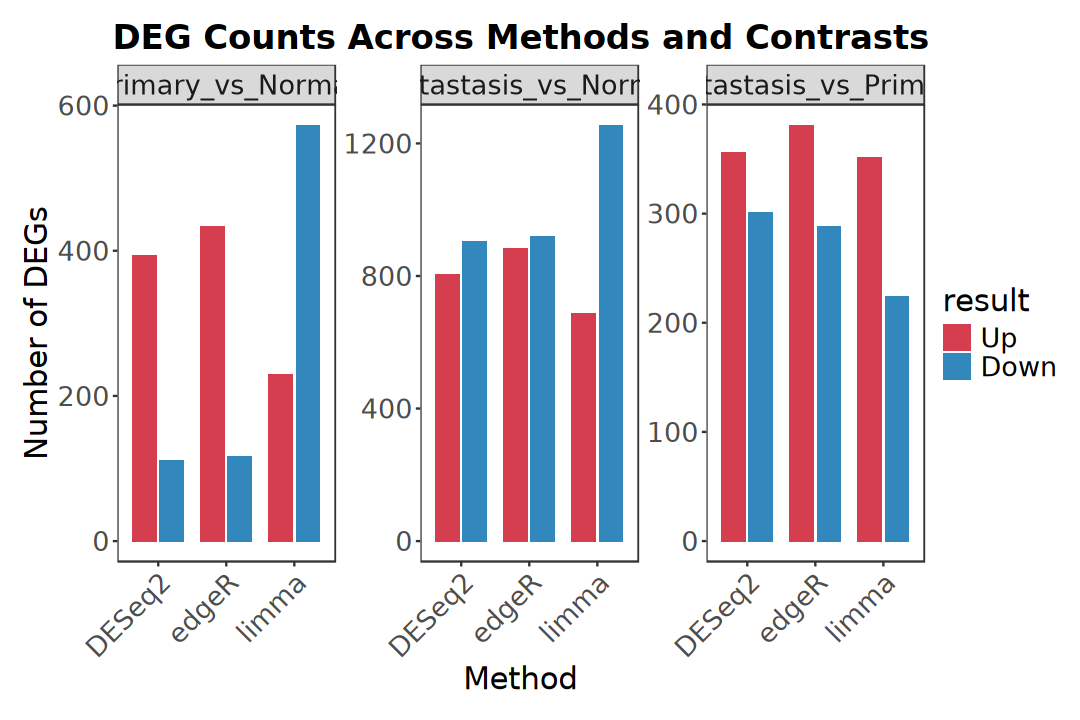

In [91]:
options(repr.plot.width = 9, repr.plot.height = 6)

all_results |> filter(result != "NS") |> 
    dplyr::count(method, contrast, result) |>
    ggplot(aes(x = method, y = n, fill = result)) +
        geom_col(position = position_dodge(width = 0.8), width = 0.7) +
        facet_wrap(~ contrast, scales = "free_y") +
        scale_fill_manual(
            values = c("Up" = "#D53E4F", "Down" = "#3288BD")) +
        labs(
            title = "DEG Counts Across Methods and Contrasts", 
            x = "Method", y = "Number of DEGs") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            strip.text = element_text(size = 16),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
            axis.text.y = element_text(size = 16))

In [92]:
# ------------------------------------------------------------------------------
# Function: summarize_software_deg_overlaps
#
# Description:
# This function computes and summarizes the overlap composition of DEG sets 
# across different software packages (e.g., DESeq2, edgeR, limma) within a contrast.
# ------------------------------------------------------------------------------
summarize_software_deg_overlaps <- function(prefix, deg_list) {
    sample_names <- grep(
        paste0("^", prefix, "_"), names(deg_list), value = TRUE)
    software_id <- str_replace_all(
        sample_names, paste0(prefix, "_"), "")
    
    comb_levels <- unlist(lapply(seq_along(software_id), function(i) {
        combn(software_id, i, FUN = function(x) 
            paste(x, collapse = "&"), simplify = TRUE)
    }), use.names = FALSE)
    
    current_list <- deg_list[sample_names]
    names(current_list) <- software_id
    
    all_genes <- unique(unlist(current_list))
    
    venn_grid <- expand.grid(rep(list(c(0, 1)), length(software_id))) |> 
        set_names(software_id)
    
    counts_df <- map_dfc(current_list, ~ as.integer(all_genes %in% .x)) |> 
        group_by(across(all_of(software_id))) |> 
        summarise(Counts = n(), .groups = "drop")
    
    venn_grid |> left_join(counts_df, by = software_id) |> 
        mutate(Counts = replace_na(Counts, 0)) |> rowwise() |> 
        mutate(
            Combination = {
                vals <- c_across(all_of(software_id))
                present <- software_id[vals == 1]
                if (length(present) == 0) "none" else 
                paste(present, collapse = "&")
            } |> factor(levels = comb_levels), 
            Group = prefix) |> 
        ungroup() |> 
        filter(Combination != "none") |> 
        dplyr::select(Group, Combination, Counts) |> 
        as.data.frame()
}

In [93]:
deg_list <- all_results |> filter(result != "NS") |> 
    mutate(list_name = paste0(contrast, "_", method)) |> 
    group_by(list_name) |> 
    summarise(genes = list(gene_id)) |> 
    deframe()

res_summary <- summarize_software_deg_overlaps("Primary_vs_Normal", deg_list)
print(res_summary)

              Group        Combination Counts
1 Primary_vs_Normal             DESeq2      9
2 Primary_vs_Normal              edgeR     41
3 Primary_vs_Normal       DESeq2&edgeR    185
4 Primary_vs_Normal              limma    467
5 Primary_vs_Normal       DESeq2&limma     12
6 Primary_vs_Normal        edgeR&limma     25
7 Primary_vs_Normal DESeq2&edgeR&limma    299


In [94]:
deg_overlap_df <- map(contrast_labels, function(con) {
    summarize_software_deg_overlaps(prefix = con, deg_list = deg_list)}) |> 
    list_rbind()

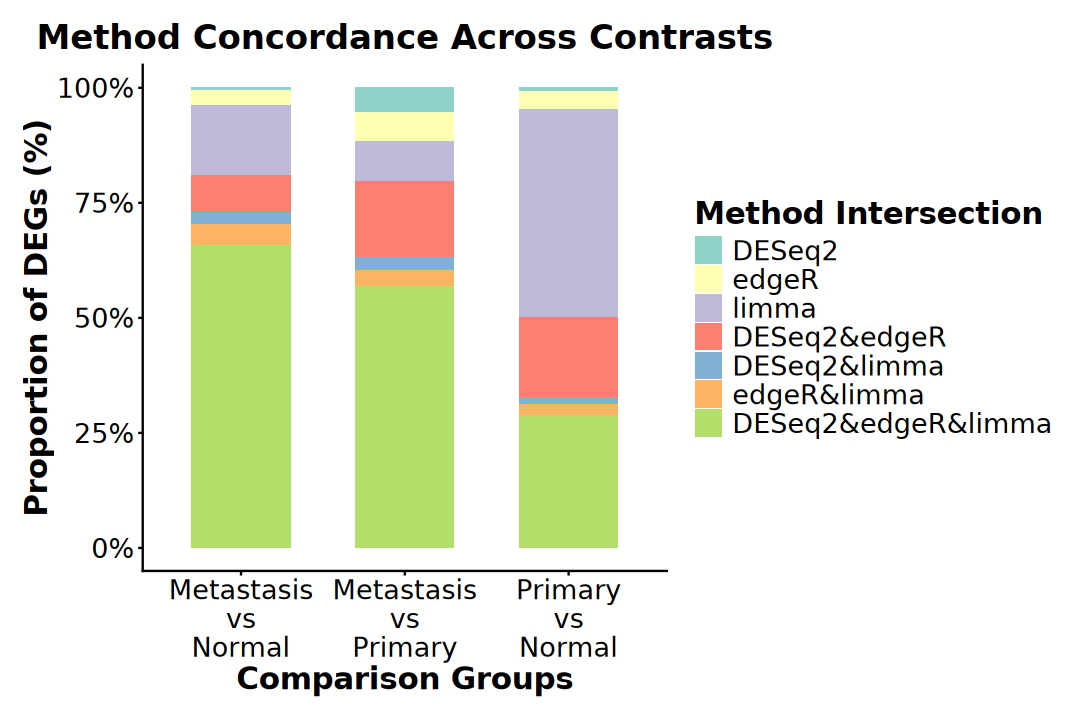

In [95]:
options(repr.plot.width = 9, repr.plot.height = 6)

deg_overlap_df |>
    mutate(Group = str_replace_all(Group, "_", "\n")) |>
    ggplot(aes(x = Group, y = Counts, fill = Combination)) +
        geom_bar(stat = "identity", position = "fill", width = 0.6) +
        scale_y_continuous(labels = scales::percent_format()) + 
        scale_fill_brewer(palette = "Set3") +
        labs(
            title = "Method Concordance Across Contrasts",
            x = "Comparison Groups", 
            y = "Proportion of DEGs (%)",
            fill = "Method Intersection"
        ) +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"), 
            legend.position = "right", 
            legend.title = element_text(size = 18, face = "bold"), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18, face = "bold"), 
            axis.text = element_text(size = 16, color = "black"))

## DEGs Visualization

In [96]:
deg_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deg_df$contrast, deg_df$result)

                       
                           Up  Down    NS
  Primary_vs_Normal       394   111 18527
  Metastasis_vs_Normal    804   904 17324
  Metastasis_vs_Primary   356   301 18375

In [97]:
max_logfc <- deg_df$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

min_padj <- deg_df$padj |> pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 5) * 5)()

### Multi-group Volcano

In [98]:
p1 <- ggplot(deg_df, aes(x = contrast, y = logFC)) + 
    geom_point(
        aes(color = result, size = result), 
        position = position_jitter(width = 0.4, height = 0), 
        na.rm = TRUE, alpha = 0.6) +
    geom_tile(
        aes(x = contrast, y = 0, fill = contrast), 
        width = 0.9, height = 1.5, show.legend = FALSE) +
    geom_text(
        aes(x = contrast, y = 0, label = contrast), 
        color = "black", size = 6) +
    geom_text_repel(
        aes(label = label), na.rm = TRUE, size = 5, 
        min.segment.length = 0, segment.size = 0.5,
        color = "black", max.overlaps = Inf) +
    scale_fill_brewer(palette = "Set2") + 
    scale_size_manual(
        values = c("Up" = 2, "Down" = 2, "NS" = 1),
        guide = "none") + 
    scale_color_manual(
        name = "DEG",
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    guides(color = guide_legend(override.aes = list(size = 5))) +
    labs(x = "Comparisons", y = "LogFC") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank(),
        axis.line.x = element_blank())

In [99]:
p2 <- ggplot(deg_df, aes(x = contrast, y = logFC)) + 
    geom_point(
        aes(color = logFC, size = result), 
        position = position_jitter(width = 0.4, height = 0), 
        na.rm = TRUE, alpha = 0.6) +
    geom_tile(
        aes(x = contrast, y = 0, fill = contrast), width = 0.9,
        height = 1.5, show.legend = FALSE) +
    geom_text(
        aes(x = contrast, y = 0, label = contrast),
        color = "black", size = 6) +
    geom_text_repel(
        aes(label = label), na.rm = TRUE, size = 5, 
        min.segment.length = 0, segment.size = 0.5,
        color = "black", max.overlaps = Inf) +
    scale_fill_brewer(palette = "Set2") + 
    scale_size_manual(
        values = c("Up" = 2, "Down" = 2, "NS" = 1),
        guide = "none") + 
    scale_color_gradientn(
        name = "logFC",
        colors = c("#39489f","#39bbec","#f9ed36","#f38466","#b81f25"), 
        limits = c(-max_logfc, max_logfc)) +
    # scale_color_viridis_c(
    #     name = "logFC", option = "turbo", begin = 0.1, end = 0.9, 
    #     limits = c(-max_logfc, max_logfc)) + 
    labs(x = "Comparisons", y = "LogFC") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank(),
        axis.line.x = element_blank())

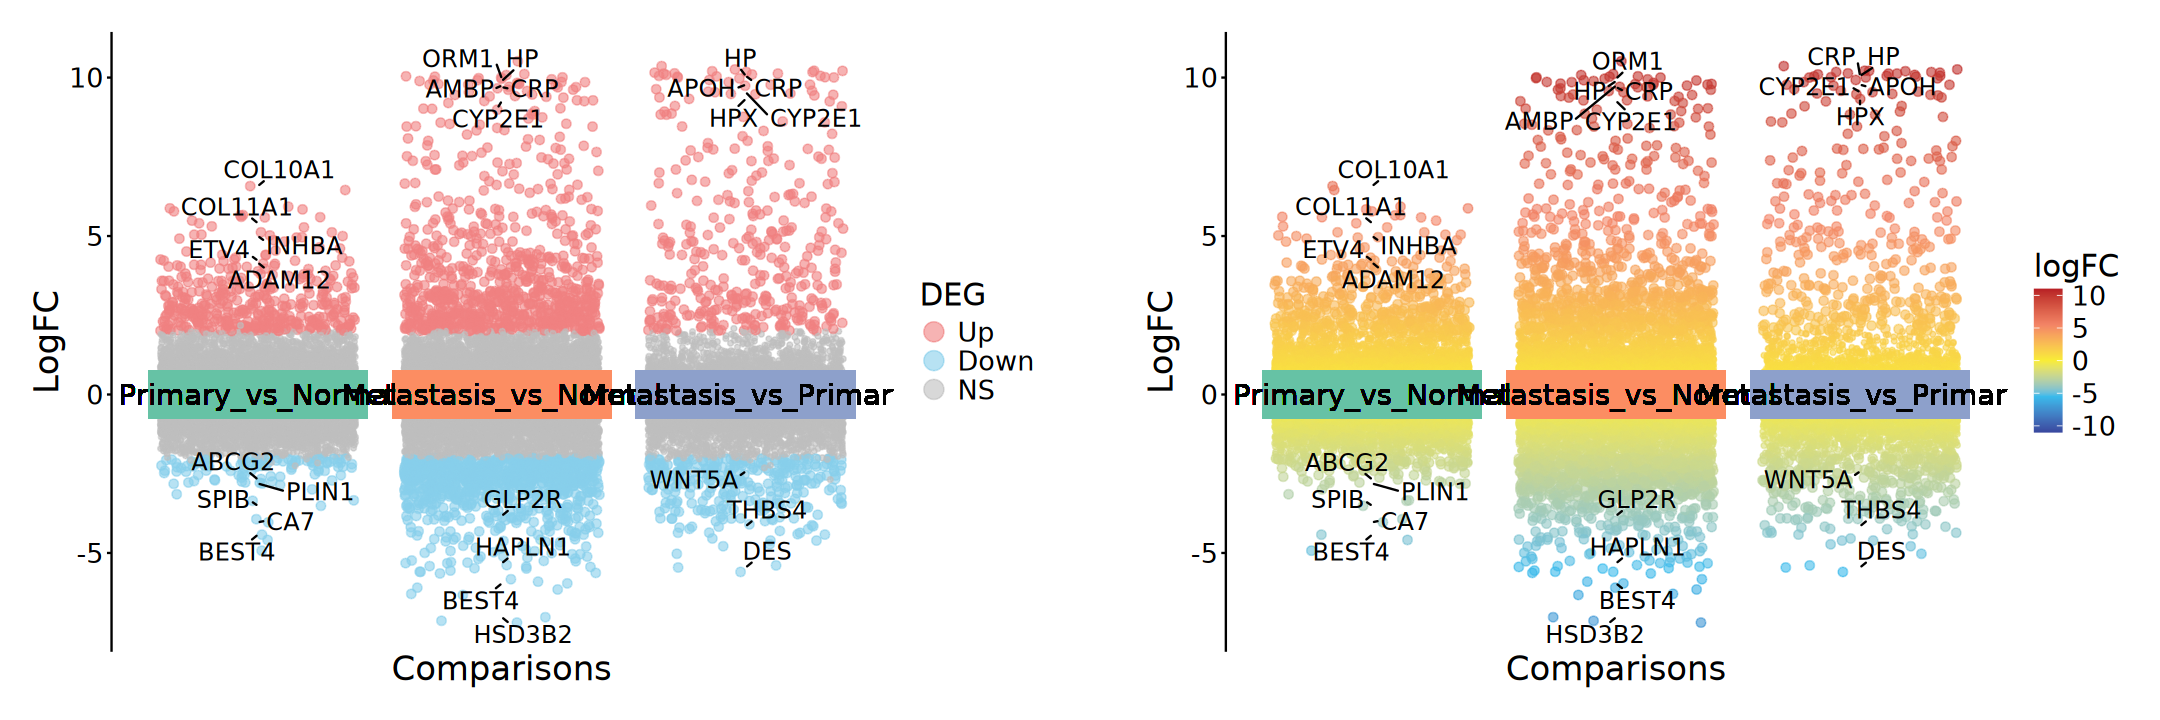

In [100]:
options(repr.plot.width = 18, repr.plot.height = 6)
p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

### Bubble Matrix Plot

In [101]:
top_genes <- all_results |> filter(result != "NS") |> 
    group_by(contrast) |> 
    slice_min(order_by = padj, n = 5) |> 
    slice_max(order_by = abs(logFC), n = 5) |> 
    pull(gene_id) |> unique()

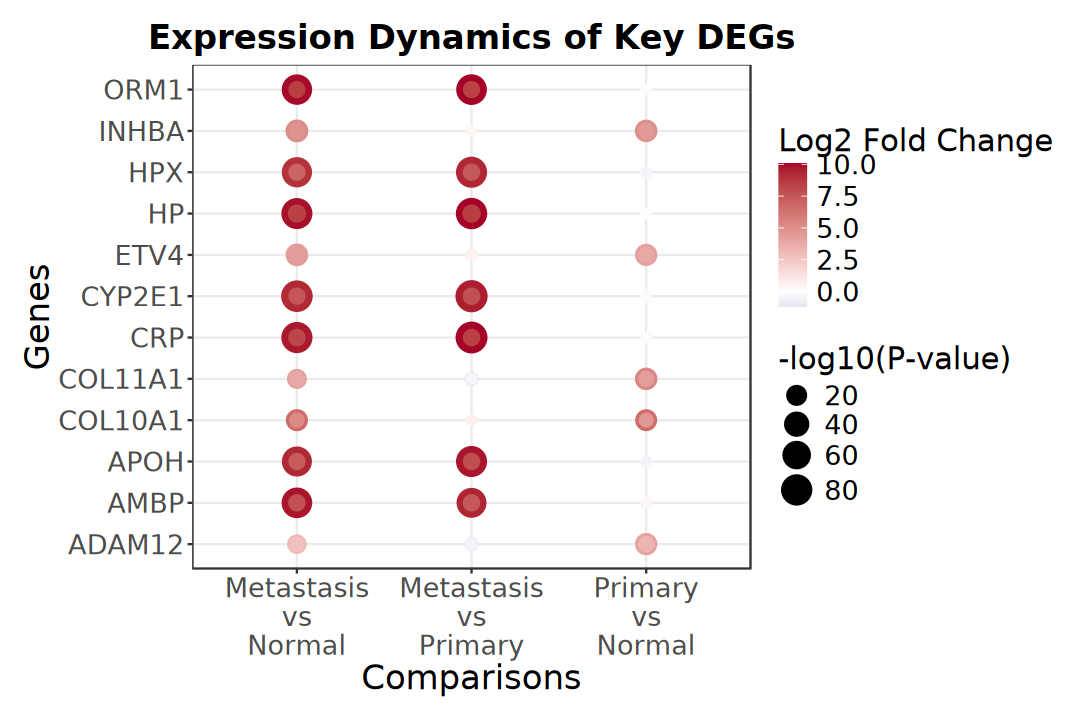

In [102]:
options(repr.plot.width = 9, repr.plot.height = 6)

all_results |> filter(gene_id %in% top_genes) |> 
    mutate(
        Group = str_replace_all(contrast, "_", "\n"),
        neg_log10P = -log10(pvalue)) |> 
    ggplot(aes(x = Group, y = symbol, size = neg_log10P, color = logFC)) +
    geom_point() +
    scale_color_gradient2(
        low = "#313695", mid = "white", high = "#a50026", 
        midpoint = 0) +
    scale_size_continuous(range = c(2, 8)) +
    labs(
        title = "Expression Dynamics of Key DEGs",
        x = "Comparisons", y = "Genes",
        color = "Log2 Fold Change", size = "-log10(P-value)") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text = element_text(size = 16))

### Heatmap

In [103]:
heatmap_dat <- deg_df |>
    filter(result %in% c("Up", "Down")) |>
    pull(gene_id) |>
    unique() |>
    (\(idx) norm_mat[idx, ])()

In [104]:
ar <- deg_df |> 
    dplyr::select(gene_id, contrast, DEG = result) |>
    pivot_wider(names_from = contrast, values_from = DEG) |> 
    column_to_rownames("gene_id") |> 
    dplyr::select(all_of(contrast_labels))


ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Group)

In [105]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- setNames(
    replicate(length(contrast_labels), deg_colors, simplify = FALSE), 
    contrast_labels) |>
    append(list(Genotype = group_colors))

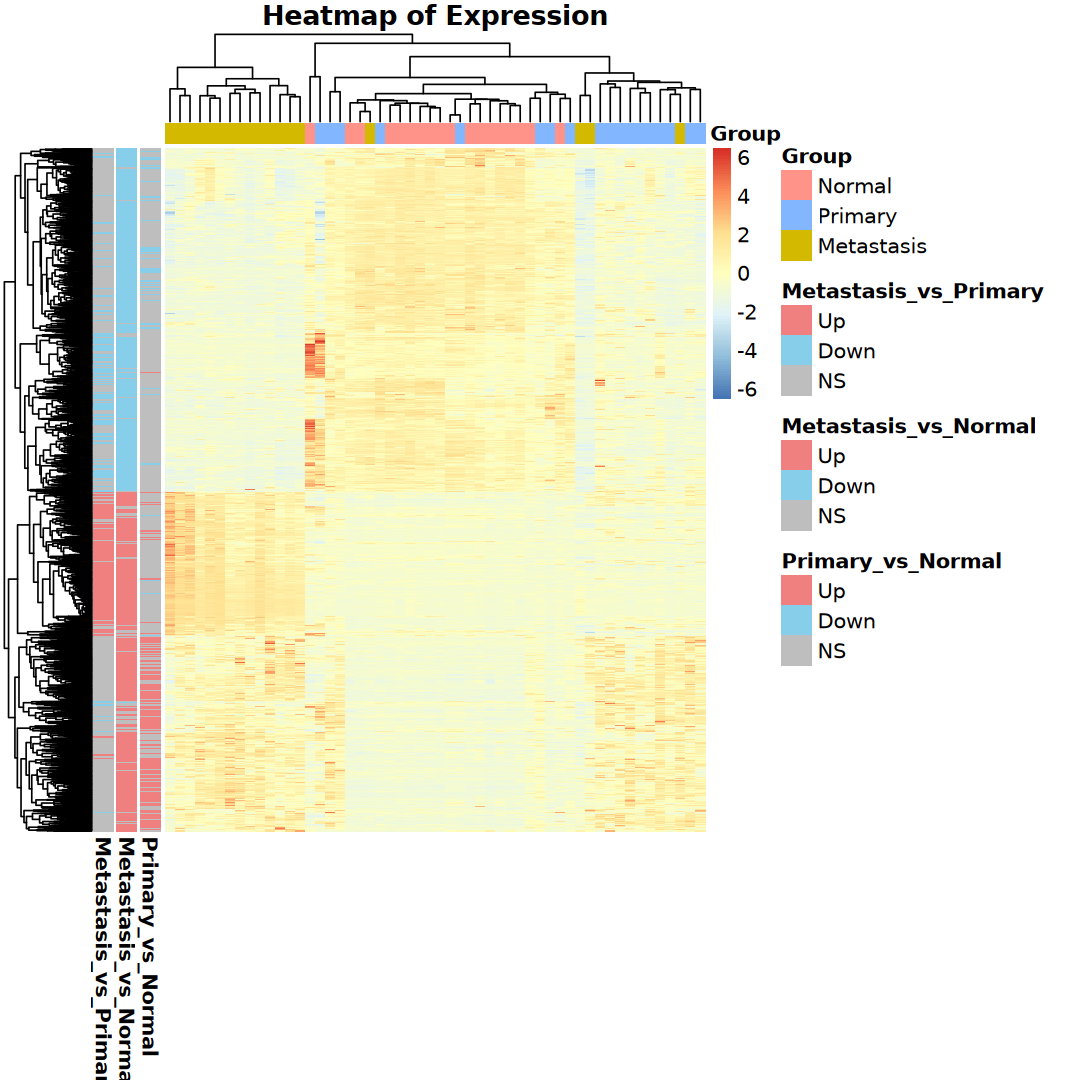

In [106]:
options(repr.plot.width = 9, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 12, 
    show_colnames = FALSE, show_rownames = FALSE)

### ComplexHeatmap

In [107]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [108]:
heatmap_dat <- deg_df |>
    filter(result %in% c("Up", "Down")) |>
    pull(gene_id) |>
    unique() |>
    (\(idx) norm_mat[idx, ])()

In [109]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = rev(brewer.pal(n = 3, name = "RdYlBu")))

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))

deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [110]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Group)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(Group = group_colors))

In [111]:
ar <- deg_df |> 
    dplyr::select(gene_id, contrast, DEG = result) |>
    pivot_wider(names_from = contrast, values_from = DEG) |> 
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id") |> 
    dplyr::select(all_of(contrast_labels))

anno_colors <- setNames(
    replicate(length(contrast_labels), deg_colors, simplify = FALSE), 
    contrast_labels)

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [112]:
gene_labels <- deg_df |>
    dplyr::filter(!is.na(label)) |>
    dplyr::select(gene_id, label)

mark_rows <- which(rownames(heatmap_dat) %in% gene_labels$gene_id)
mark_labels <- gene_labels$label[
    match(rownames(heatmap_dat)[mark_rows], gene_labels$gene_id)]

right_anno <- rowAnnotation(
    foo = anno_mark(
        at = mark_rows,
        labels = mark_labels,
        labels_gp = gpar(fontsize = 12)))

In [113]:
lg_heatmap <- Legend(title = "Expression (z-score)",
                     col_fun = heatmap_col)

lg_group <- Legend(title = "Group", 
                   labels = levels(dds$Group))

lg_deg <- Legend(labels = levels(deg_df$result), title = "DEG", 
                 legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group) |>
    packLegend(direction = "vertical")

In [114]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(name = "Expression", col = heatmap_col,
            top_annotation = top_anno,
            left_annotation = left_anno, 
            right_annotation = right_anno,
            show_row_names = FALSE, 
            show_column_names = FALSE, 
            use_raster = TRUE)

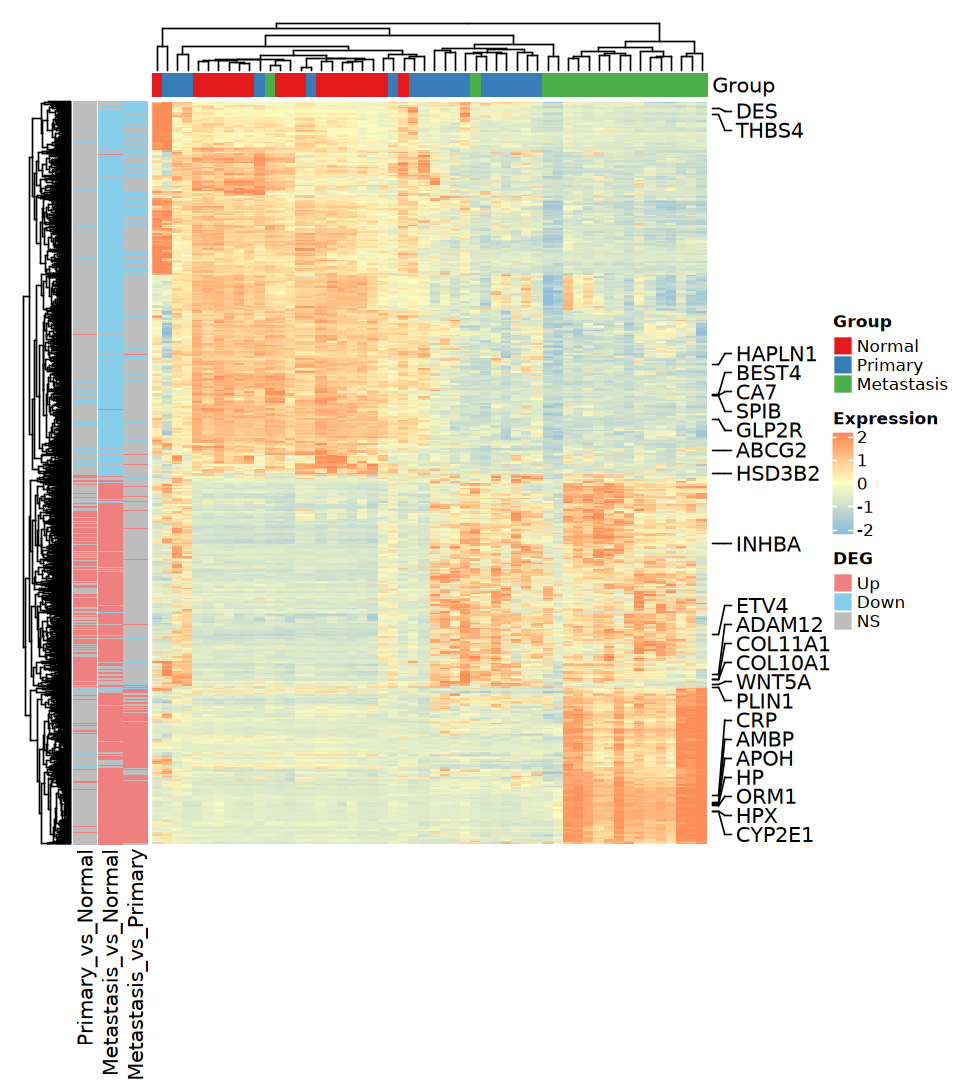

In [115]:
options(repr.plot.width = 8, repr.plot.height = 9)
draw(ht + combined_leg, merge_legend = TRUE,
     annotation_legend_list = list(lg_deg), 
     legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
     legend_labels_gp = gpar(fontsize = 10), 
     padding = unit(c(5, 5, 5, 5), "mm"))

# 6. Gene Function Analysis

## 1). ORA

> Over-Representation Analysis

In [116]:
suppressPackageStartupMessages(library(org.Hs.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [117]:
add_ENTREZID <- function(
    res, col, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = FALSE) {
    
    gene_ids <- res[[col]]

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }
    
    return(res)
}

In [118]:
deg_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deg_df$contrast, deg_df$result)

                       
                           Up  Down    NS
  Primary_vs_Normal       394   111 18527
  Metastasis_vs_Normal    804   904 17324
  Metastasis_vs_Primary   356   301 18375

In [119]:
deg_df <- add_ENTREZID(
    deg_df, "gene_id", org.Hs.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"10.77% of input gene IDs are fail to map..."


In [120]:
deg_types <- c("Up", "Down")

genes_list <- crossing(comp = contrast_labels, deg = deg_types) |>
    pmap(~ deg_df$symbol[deg_df$result == .y & deg_df$contrast == .x]) |>
    set_names(paste(
        contrast_labels, rep(deg_types, each = length(contrast_labels)), 
        sep = "_")) |>
    map(unique)

In [121]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = unique(deg_df$SYMBOL), 
    OrgDb = org.Hs.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [122]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,Primary_vs_Normal_Up,BP,GO:0050804,modulation of chemical synaptic transmission,56/653,428/13968,0.1308411,2.798758,8.369949,2.210762e-12,4.646560e-09,4.100904e-09,56
2,Primary_vs_Normal_Up,BP,GO:0099177,regulation of trans-synaptic signaling,56/653,429/13968,0.1305361,2.792234,8.349637,2.433391e-12,4.646560e-09,4.100904e-09,56
3,Primary_vs_Normal_Up,BP,GO:0042391,regulation of membrane potential,50/653,361/13968,0.1385042,2.962674,8.366776,4.250483e-12,5.410865e-09,4.775455e-09,50
4,Primary_vs_Normal_Up,BP,GO:0007188,adenylate cyclase-modulating G protein-coupled receptor signaling pathway,32/653,191/13968,0.1675393,3.583750,7.962095,2.723075e-10,2.334683e-07,2.060516e-07,32
5,Primary_vs_Normal_Up,BP,GO:0061564,axon development,54/653,458/13968,0.1179039,2.522025,7.334395,3.056668e-10,2.334683e-07,2.060516e-07,54
6,Primary_vs_Normal_Up,BP,GO:0007411,axon guidance,32/653,207/13968,0.1545894,3.306745,7.404527,2.202408e-09,1.358511e-06,1.198978e-06,32


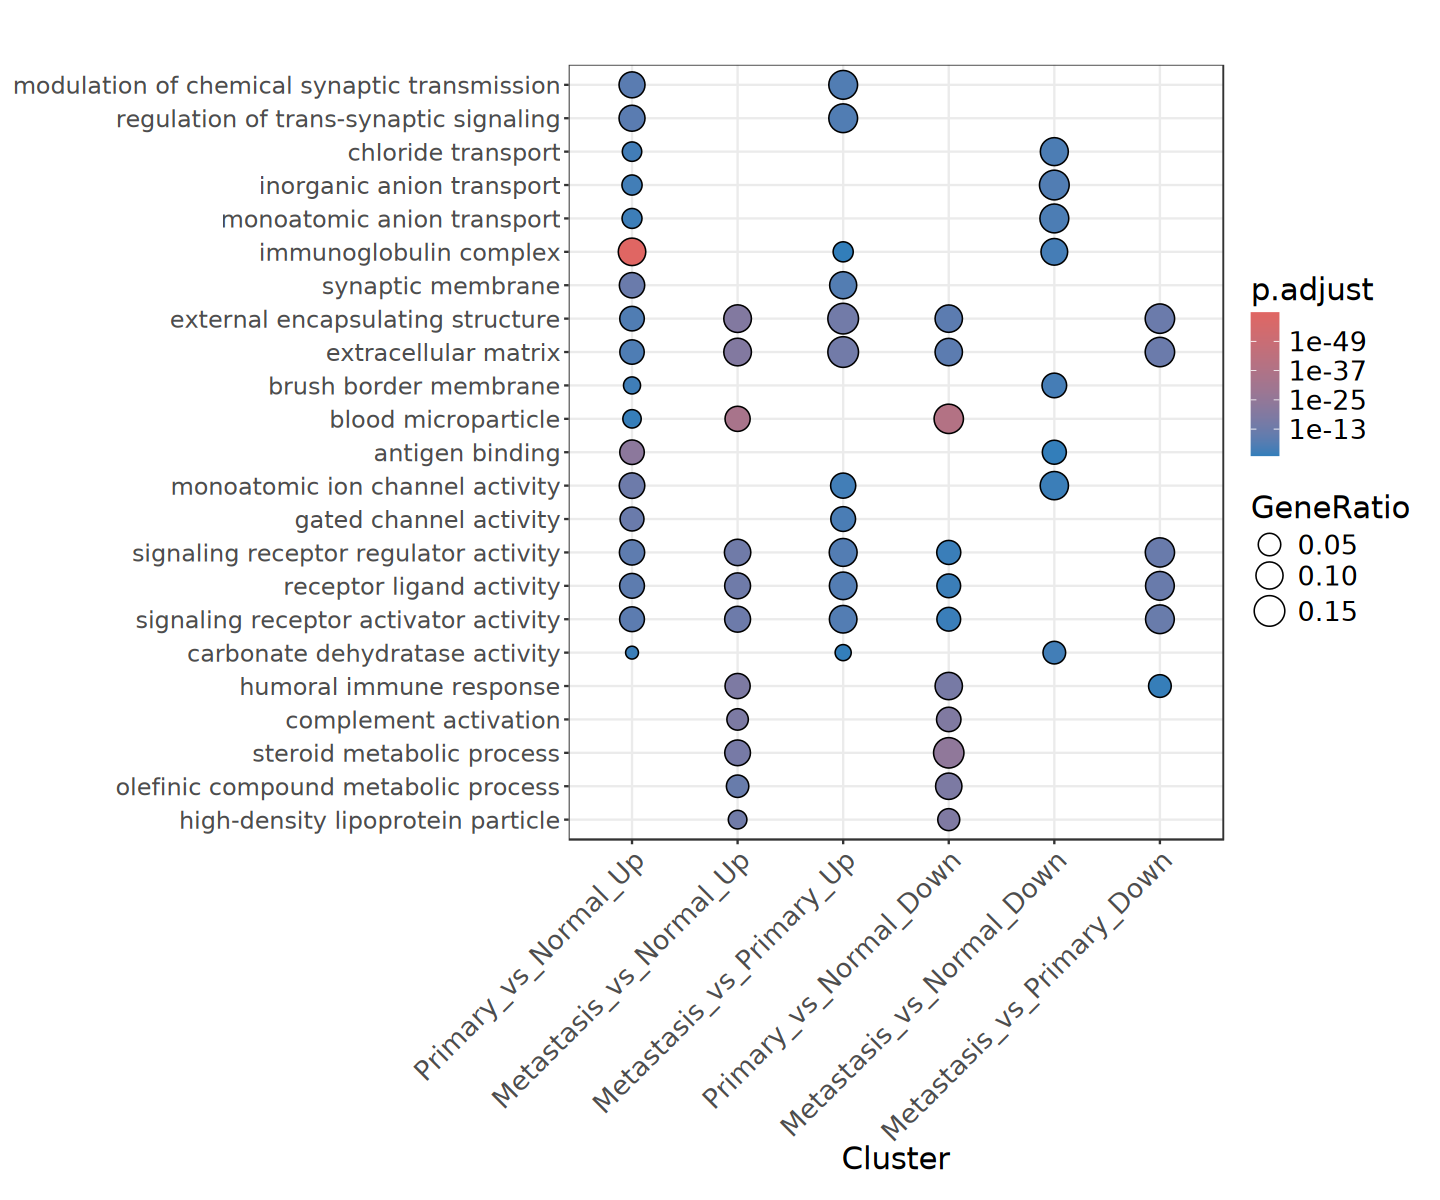

In [129]:
options(repr.plot.width = 12, repr.plot.height = 10)

dotplot(ego_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [124]:
deg_types <- c("Up", "Down")

genes_list <- crossing(comp = contrast_labels, deg = deg_types) |>
    pmap(~ deg_df$ENTREZID[deg_df$result == .y & deg_df$contrast == .x]) |>
    set_names(paste(
        contrast_labels, rep(deg_types, each = length(contrast_labels)), 
        sep = "_")) |>
    map(unique)

In [125]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, 
    universe = unique(deg_df$ENTREZID), 
    organism = "hsa", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

Warning message in file(file, "rt"):
"URL 'https://raw.githubusercontent.com/YuLab-SMU/clusterProfiler/refs/heads/gh-pages/md5.txt': Timeout of 60 seconds was reached"
Warning message in file(file, "rt"):
"URL 'https://raw.githubusercontent.com/YuLab-SMU/clusterProfiler/refs/heads/gh-pages/md5.txt': Timeout of 60 seconds was reached"
Warning message in file(file, "rt"):
"URL 'https://raw.githubusercontent.com/YuLab-SMU/clusterProfiler/refs/heads/gh-pages/md5.txt': Timeout of 60 seconds was reached"


In [126]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,Primary_vs_Normal_Up,Environmental Information Processing,Signaling molecules and interaction,hsa04080,Neuroactive ligand-receptor interaction,47/306,199/6842,0.2361809,5.280882,13.259957,3.594626e-22,8.986566e-20,8.021693e-20,47
2,Primary_vs_Normal_Up,Environmental Information Processing,Signaling molecules and interaction,hsa04082,Neuroactive ligand signaling,26/306,125/6842,0.2080000,4.650771,8.912847,2.611964e-11,3.264954e-09,2.914401e-09,26
3,Primary_vs_Normal_Up,Environmental Information Processing,Signal transduction,hsa04020,Calcium signaling pathway,27/306,201/6842,0.1343284,3.003512,6.237890,2.312504e-07,1.927087e-05,1.720179e-05,27
4,Primary_vs_Normal_Up,Environmental Information Processing,Signal transduction,hsa04024,cAMP signaling pathway,24/306,178/6842,0.1348315,3.014761,5.892920,1.041725e-06,6.510783e-05,5.811730e-05,24
5,Primary_vs_Normal_Up,Human Diseases,Substance dependence,hsa05033,Nicotine addiction,8/306,23/6842,0.3478261,7.777209,7.043994,3.978142e-06,1.989071e-04,1.775508e-04,8
6,Primary_vs_Normal_Up,Organismal Systems,Endocrine system,hsa04924,Renin secretion,12/306,60/6842,0.2000000,4.471895,5.844237,1.045249e-05,4.355204e-04,3.887592e-04,12


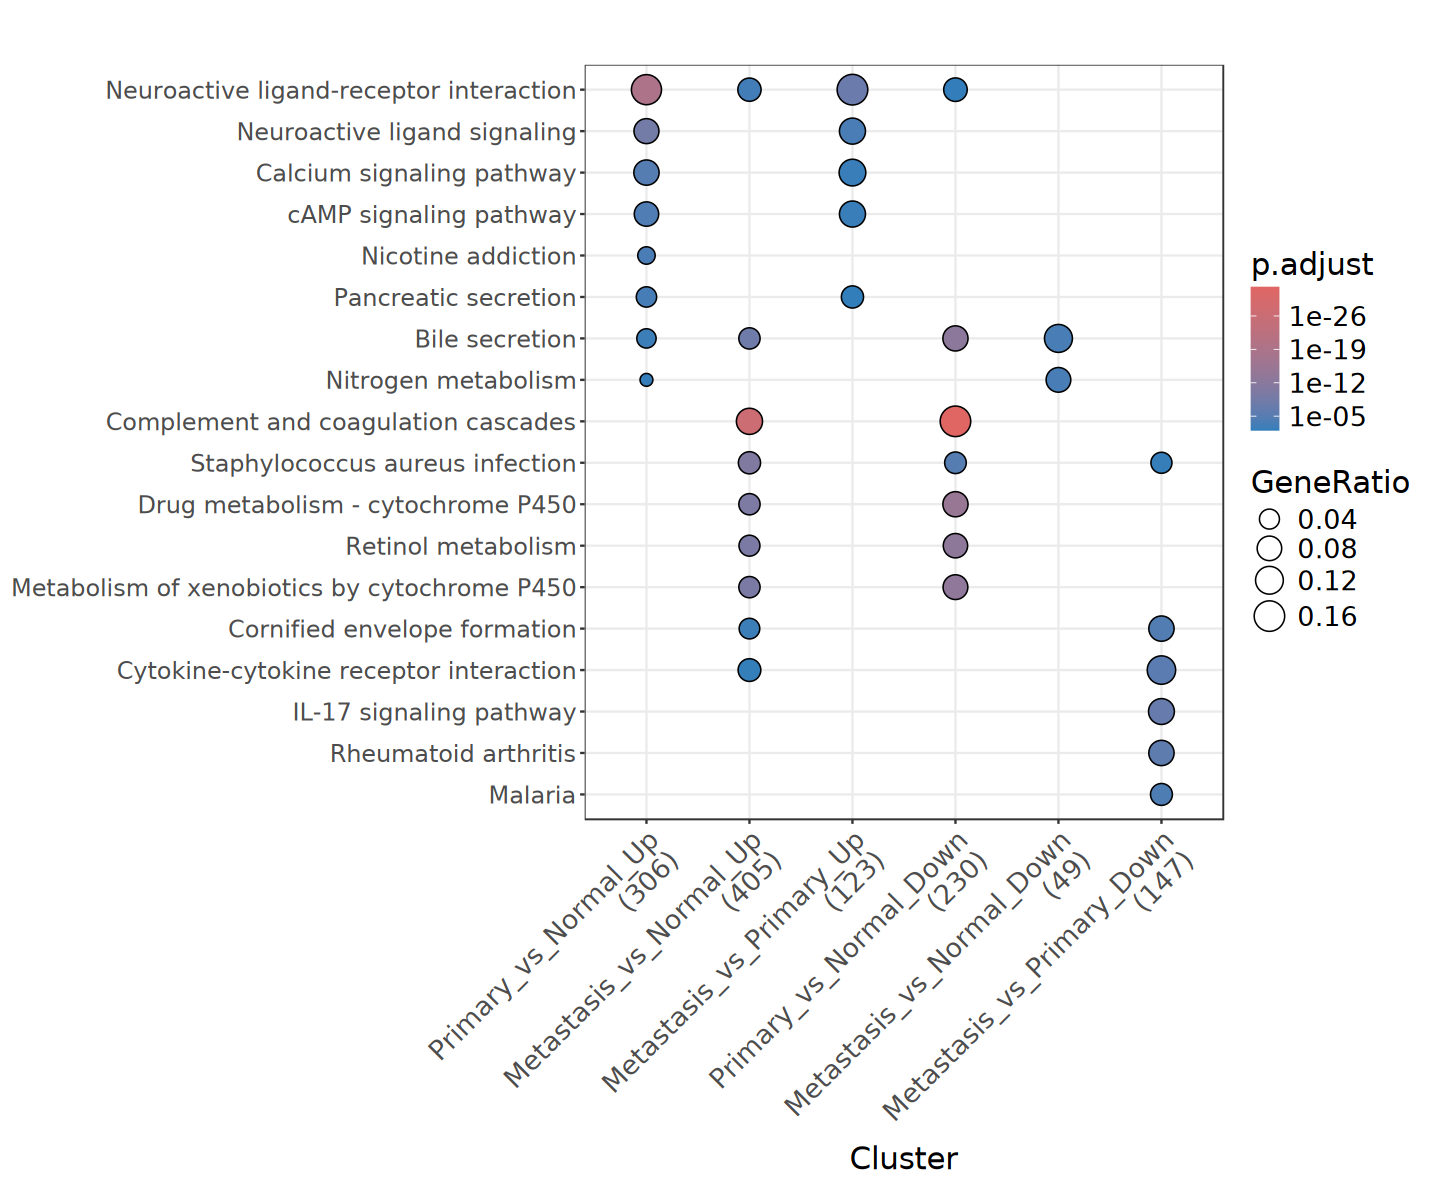

In [128]:
options(repr.plot.width = 12, repr.plot.height = 10)

dotplot(ekegg_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)